In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/telco_clean.csv")
sns.set_theme(style="whitegrid")
print(df.shape)
print("Overall churn rate:", round(df["Churn"].mean() * 100, 1), "%")

(7043, 20)
Overall churn rate: 26.5 %


Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


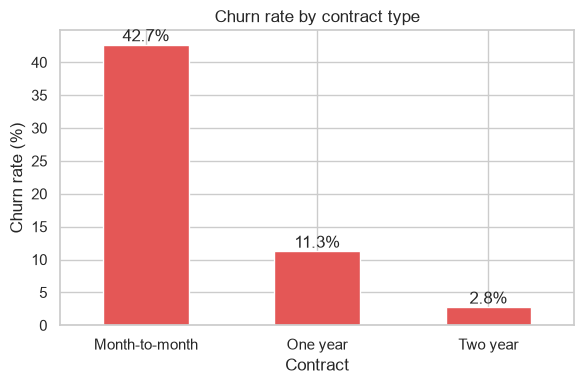

In [2]:
rate = df.groupby("Contract")["Churn"].mean().mul(100).round(1)
print(rate)

ax = rate.sort_values(ascending=False).plot(kind="bar", color="#e45756", figsize=(6, 4))
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by contract type")
plt.xticks(rotation=0)
for i, v in enumerate(rate.sort_values(ascending=False)):
    ax.text(i, v + 0.5, f"{v}%", ha="center")
plt.tight_layout()
plt.savefig("churn_by_contract.png", dpi=150)
plt.show()

### Insight 1: Contract type is the strongest warning sign
Month-to-month customers churn at 42.7%, compared with 11.3% on one-year contracts and 2.8% on two-year contracts. A month-to-month customer is about 15 times more likely to leave than a two-year customer.

**Business action:** offer discounts or perks to move month-to-month customers onto longer contracts.

tenure_group
0-12 mo     47.4
13-24 mo    28.7
25-48 mo    20.4
49-72 mo     9.5
Name: Churn, dtype: float64


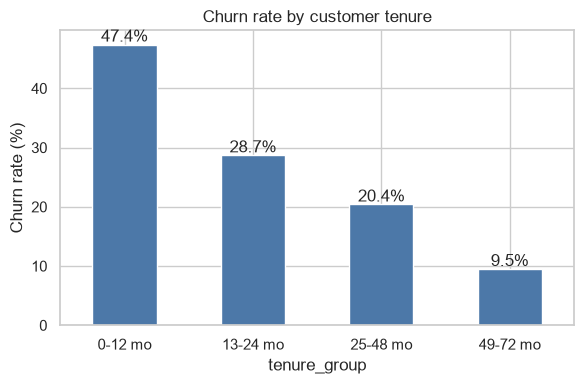

In [3]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"])
rate = df.groupby("tenure_group", observed=True)["Churn"].mean().mul(100).round(1)
print(rate)

ax = rate.plot(kind="bar", color="#4c78a8", figsize=(6, 4))
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by customer tenure")
plt.xticks(rotation=0)
for i, v in enumerate(rate):
    ax.text(i, v + 0.5, f"{v}%", ha="center")
plt.tight_layout()
plt.savefig("churn_by_tenure.png", dpi=150)
plt.show()

### Insight 2: The first year is the danger zone
Customers in their first 12 months churn at 47.4%. The rate falls steadily with tenure: 28.7% (13-24 months), 20.4% (25-48 months), and only 9.5% after 4 years.

**Business action:** focus retention efforts (onboarding calls, check-ins, early offers) on new customers, because that's where nearly half leave.

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64


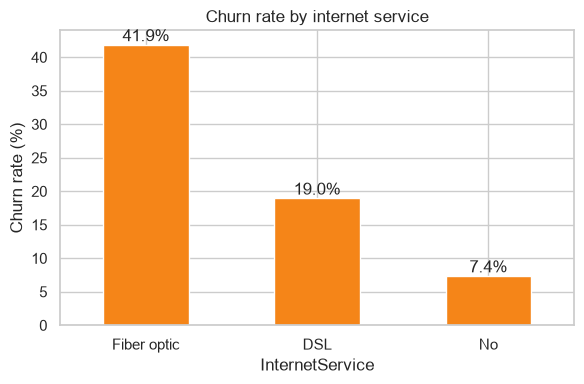

In [4]:
rate = df.groupby("InternetService")["Churn"].mean().mul(100).round(1)
print(rate)

ax = rate.sort_values(ascending=False).plot(kind="bar", color="#f58518", figsize=(6, 4))
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by internet service")
plt.xticks(rotation=0)
for i, v in enumerate(rate.sort_values(ascending=False)):
    ax.text(i, v + 0.5, f"{v}%", ha="center")
plt.tight_layout()
plt.savefig("churn_by_internet.png", dpi=150)
plt.show()

In [ ]:
### Insight 3: Fiber optic customers leave far more than DSL customers
Fiber optic churn is 41.9%, against 19.0% for DSL and 7.4% for customers with no internet service. Fiber customers also pay much
more on average ($91.50 vs $58.10 per month), so price may be a key driver. The model's explainability step (SHAP) will help 
separate price from service type.

**Business action:** investigate fiber optic customers specifically, looking at price, service quality, and competitors.

print(df.groupby("InternetService")["MonthlyCharges"].mean().round(2))

**InternetService
DSL            58.10
Fiber optic    91.50
No             21.08
Name: MonthlyCharges, dtype: float64**